# Full benchmark: all 18 datasets, all methods, all statistical tests

Runs everything end to end and stores it under `results/<EXPERIMENT_NAME>/`:

1. **Main experiment**: K-Means, FCM, EAC, ACE, Fuzzy-ACE × 18 datasets (12 UCI + 6 SIPU) × {fixed, variable} k × `N_RUNS` seeded runs, scored with ARI and NMI.
2. **Statistical tests**: Friedman + Iman-Davenport, then Nemenyi post-hoc and CD diagrams, on all datasets and on three subsets (ACE paper, fuzzy hypothesis, SIPU).
3. **α₂ sensitivity**: grid search of the certainty threshold for ACE and Fuzzy-ACE.

Every finished run is written to disk immediately, so re-running the notebook after an interruption resumes where it left off.
Birch1-3 (n = 100,000) are replaced by one fixed stratified subsample of `MAX_INSTANCES` points (EAC needs an n × n matrix).
The full run takes hours; set `QUICK = True` first to check that everything works in a few minutes.

In [1]:
%load_ext autoreload
%autoreload 2

import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.datasets import (ACE_PAPER_DATASETS, ALL_DATASETS, FUZZY_HYPOTHESIS_DATASETS, SIPU_DATASETS,
                          dataset_overview)
from src.experiments import METHODS, ExperimentConfig, run_alpha2_grid_search, run_experiment
from src.stats_tests import run_statistical_tests

pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
RESULTS_DIR = ROOT / "results"
print("Project root:", ROOT)

Project root: C:\Users\lukas\PycharmProjects\FuzzyAdaptiveClusteringEnsemble


## Parameters

In [2]:
QUICK = False                  # True: 2 runs on 4 small datasets, to test the pipeline quickly

EXPERIMENT_NAME = "full"
DATASETS = list(ALL_DATASETS)
N_RUNS = 10
N_JOBS = -1                    # parallel workers (-1 = all cores); lower it if memory runs out
MAX_INSTANCES = 5000           # Birch subsample size (None = all 100,000 points; not feasible for EAC)
VERBOSE = True                 # print one line per finished run

STATS_ALPHA = 0.1
STATS_SUBSETS = {"": DATASETS, "ace_paper": ACE_PAPER_DATASETS,
                 "fuzzy_hypothesis": FUZZY_HYPOTHESIS_DATASETS, "sipu": SIPU_DATASETS}

ALPHA2_VALUES = [0.5, 0.6, 0.7, 0.8, 0.9]
ALPHA2_DATASETS = list(ALL_DATASETS)
ALPHA2_SETTINGS = ["fixed", "variable"]

if QUICK:
    EXPERIMENT_NAME, N_RUNS = "full_quick", 2
    DATASETS = ALPHA2_DATASETS = ["iris", "wine", "unbalance", "dim032"]
    STATS_SUBSETS = {"": DATASETS}

cfg = ExperimentConfig(name=EXPERIMENT_NAME, datasets=DATASETS, n_runs=N_RUNS, n_jobs=N_JOBS,
                       max_instances=MAX_INSTANCES, results_dir=str(RESULTS_DIR))
exp_dir = RESULTS_DIR / EXPERIMENT_NAME
grid_dir = RESULTS_DIR / f"{EXPERIMENT_NAME}_alpha2"
cfg

ExperimentConfig(name='full', datasets=['iris', 'wine', 'new_thyroid', 'glass', 'breast_cancer', 'soybean_small', 'ionosphere', 'ecoli', 'yeast', 'vehicle', 'image_segmentation', 'dermatology', 'birch1', 'birch2', 'birch3', 'unbalance', 'dim032', 'dim064'], settings=['fixed', 'variable'], methods=['KMeans', 'FCM', 'EAC', 'ACE', 'Fuzzy-ACE'], n_runs=10, base_seed=0, m_partitions=10, sampling_ratio=0.7, alpha_1=0.8, alpha_2=0.7, delta_alpha=0.1, fcm_m_fuzz=2.0, fuzzy_ace_m_range=(1.5, 2.5), kmeans_n_init=1, eac_linkage='average', max_instances=5000, subsample_seed=0, data_dir='C:\\Users\\lukas\\PycharmProjects\\FuzzyAdaptiveClusteringEnsemble\\data\\raw', results_dir='C:\\Users\\lukas\\PycharmProjects\\FuzzyAdaptiveClusteringEnsemble\\results', n_jobs=-1)

## 1. Datasets

In [3]:
overview = dataset_overview().set_index("key").loc[DATASETS]
overview["n_used"] = [min(n, MAX_INSTANCES) if MAX_INSTANCES else n for n in overview["n"]]
overview["group"] = ["ACE paper" if k in ACE_PAPER_DATASETS else
                     "fuzzy hypothesis" if k in FUZZY_HYPOTHESIS_DATASETS else "SIPU" for k in overview.index]
missing = overview.index[~overview["available"]].tolist()
if missing:
    print("Missing raw files (these will be skipped):", missing, "-> run: bash data/download_uci.sh")
overview

,name,available,n,d,k,missing_values,n_used,group
key,,,,,,,,
iris,Iris,True,150,4,3,0,150,ACE paper
wine,Wine,True,178,13,3,0,178,ACE paper
new_thyroid,New-Thyroid,True,215,5,3,0,215,ACE paper
glass,Glass,True,214,9,6,0,214,ACE paper
breast_cancer,Breast Cancer (Original),True,699,9,2,16,699,ACE paper
soybean_small,Soybean (Small),True,47,35,4,0,47,ACE paper
ionosphere,Ionosphere,True,351,34,2,0,351,ACE paper
ecoli,Ecoli,True,336,7,8,0,336,fuzzy hypothesis
yeast,Yeast,True,1484,8,10,0,1484,fuzzy hypothesis


## 2. Main experiment

In [4]:
t0 = time.perf_counter()
raw = run_experiment(cfg, resume=True, verbose=VERBOSE)
print(f"{len(raw)} runs stored, {int((raw['status'] != 'ok').sum())} failed, "
      f"this session {(time.perf_counter() - t0) / 60:.1f} min")

[full] 210 runs to do (1590 already stored) -> C:\Users\lukas\PycharmProjects\FuzzyAdaptiveClusteringEnsemble\results\full
  [1/210] variable birch2             Fuzzy-ACE run 2: ARI=0.4434 NMI=0.7946 (568.4s) ok
  [2/210] variable birch2             Fuzzy-ACE run 4: ARI=0.6879 NMI=0.9224 (610.5s) ok
  [3/210] variable birch2             Fuzzy-ACE run 3: ARI=0.6743 NMI=0.9166 (646.7s) ok
  [4/210] variable birch3             KMeans    run 0: ARI=0.7268 NMI=0.9126 (0.3s) ok
  [5/210] variable birch3             KMeans    run 1: ARI=0.7537 NMI=0.9089 (0.1s) ok
  [6/210] variable birch3             KMeans    run 2: ARI=0.7259 NMI=0.9082 (0.1s) ok
  [7/210] variable birch3             KMeans    run 3: ARI=0.7952 NMI=0.9228 (0.1s) ok
  [8/210] variable birch3             KMeans    run 4: ARI=0.7900 NMI=0.9215 (0.1s) ok
  [9/210] variable birch3             KMeans    run 5: ARI=0.7885 NMI=0.9197 (0.1s) ok
  [10/210] variable birch3             KMeans    run 6: ARI=0.7378 NMI=0.9147 (0.1s) ok


In [5]:
failed = raw[raw["status"] != "ok"]
if len(failed):
    display(failed[["setting", "dataset", "method", "run", "error"]])
else:
    print("No failed runs.")

No failed runs.


### Mean ± std per dataset (last row: average over datasets)

In [6]:
for setting in cfg.settings:
    for metric in ("ari", "nmi"):
        print(f"\n{metric.upper()} - {setting} k")
        display(pd.read_csv(exp_dir / "tables" / f"{metric}_{setting}.csv", index_col=0))


ARI - fixed k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6071 ± 0.066,0.6303 ± 0.0,0.6158 ± 0.031,0.6193 ± 0.0284,0.6262 ± 0.0235
wine,0.8941 ± 0.0213,0.8975 ± 0.0,0.8955 ± 0.0377,0.8904 ± 0.0283,0.7099 ± 0.1488
new_thyroid,0.5917 ± 0.0074,0.6592 ± 0.0,0.5744 ± 0.0464,0.5572 ± 0.0496,0.3026 ± 0.1998
glass,0.1923 ± 0.0433,0.1534 ± 0.0011,0.1937 ± 0.0338,0.1718 ± 0.0295,0.1491 ± 0.0355
breast_cancer,0.8285 ± 0.009,0.802 ± 0.0,0.8205 ± 0.0135,0.8232 ± 0.009,0.8168 ± 0.016
soybean_small,0.8863 ± 0.1513,1.0 ± 0.0,0.989 ± 0.0235,0.9953 ± 0.0148,0.8652 ± 0.1981
ionosphere,0.1698 ± 0.0025,0.1587 ± 0.0,0.1666 ± 0.0091,0.1578 ± 0.0144,0.1608 ± 0.0189
ecoli,0.4989 ± 0.0614,0.3752 ± 0.0123,0.5183 ± 0.0633,0.4123 ± 0.2414,0.4041 ± 0.0602
yeast,0.1745 ± 0.0118,0.126 ± 0.0005,0.1746 ± 0.0079,0.1786 ± 0.0123,0.1385 ± 0.0363



NMI - fixed k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6521 ± 0.0249,0.6659 ± 0.0,0.6524 ± 0.0242,0.6574 ± 0.0213,0.6607 ± 0.0211
wine,0.875 ± 0.0154,0.8759 ± 0.0,0.8778 ± 0.0345,0.872 ± 0.0257,0.7495 ± 0.0919
new_thyroid,0.5652 ± 0.0054,0.6245 ± 0.0,0.5472 ± 0.0404,0.5323 ± 0.0445,0.3252 ± 0.1806
glass,0.3423 ± 0.0556,0.3069 ± 0.0007,0.3421 ± 0.0305,0.3108 ± 0.0306,0.2818 ± 0.038
breast_cancer,0.7225 ± 0.0112,0.6925 ± 0.0,0.7134 ± 0.016,0.7163 ± 0.011,0.7099 ± 0.019
soybean_small,0.9299 ± 0.0942,1.0 ± 0.0,0.9892 ± 0.0228,0.9948 ± 0.0164,0.9155 ± 0.1187
ionosphere,0.1269 ± 0.0025,0.1195 ± 0.0,0.1238 ± 0.009,0.1152 ± 0.014,0.17 ± 0.0384
ecoli,0.6197 ± 0.0262,0.557 ± 0.0091,0.6359 ± 0.0213,0.5206 ± 0.1621,0.5721 ± 0.0265
yeast,0.2988 ± 0.0056,0.1585 ± 0.0008,0.2997 ± 0.0062,0.2979 ± 0.0036,0.2508 ± 0.0288



ARI - variable k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6071 ± 0.066,0.6303 ± 0.0,0.5902 ± 0.0287,0.607 ± 0.0358,0.5976 ± 0.0413
wine,0.8941 ± 0.0213,0.8975 ± 0.0,0.8351 ± 0.0798,0.815 ± 0.1044,0.5067 ± 0.1865
new_thyroid,0.5917 ± 0.0074,0.6592 ± 0.0,0.6049 ± 0.0566,0.4279 ± 0.0851,0.1999 ± 0.2013
glass,0.1923 ± 0.0433,0.1534 ± 0.0011,0.1948 ± 0.0451,0.1867 ± 0.0344,0.1317 ± 0.0385
breast_cancer,0.8285 ± 0.009,0.802 ± 0.0,0.8667 ± 0.0219,0.7837 ± 0.0596,0.82 ± 0.0465
soybean_small,0.8863 ± 0.1513,1.0 ± 0.0,0.9674 ± 0.1032,0.7622 ± 0.2664,0.5936 ± 0.186
ionosphere,0.1698 ± 0.0025,0.1587 ± 0.0,0.1733 ± 0.0063,0.1341 ± 0.0858,0.1448 ± 0.0205
ecoli,0.4989 ± 0.0614,0.3752 ± 0.0123,0.5175 ± 0.0703,0.5457 ± 0.095,0.4242 ± 0.0366
yeast,0.1745 ± 0.0118,0.126 ± 0.0005,0.1732 ± 0.0099,0.169 ± 0.0407,0.1237 ± 0.0302



NMI - variable k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6521 ± 0.0249,0.6659 ± 0.0,0.6548 ± 0.0239,0.6978 ± 0.0366,0.6455 ± 0.0465
wine,0.875 ± 0.0154,0.8759 ± 0.0,0.8236 ± 0.0599,0.8139 ± 0.0792,0.5898 ± 0.1338
new_thyroid,0.5652 ± 0.0054,0.6245 ± 0.0,0.5759 ± 0.0498,0.439 ± 0.0579,0.2673 ± 0.1404
glass,0.3423 ± 0.0556,0.3069 ± 0.0007,0.3383 ± 0.0479,0.3201 ± 0.0269,0.2773 ± 0.031
breast_cancer,0.7225 ± 0.0112,0.6925 ± 0.0,0.7744 ± 0.0294,0.6739 ± 0.0685,0.7188 ± 0.0535
soybean_small,0.9299 ± 0.0942,1.0 ± 0.0,0.9823 ± 0.056,0.8557 ± 0.1625,0.7501 ± 0.1166
ionosphere,0.1269 ± 0.0025,0.1195 ± 0.0,0.1313 ± 0.0065,0.1121 ± 0.0434,0.1424 ± 0.03
ecoli,0.6197 ± 0.0262,0.557 ± 0.0091,0.628 ± 0.0298,0.611 ± 0.0358,0.5683 ± 0.0124
yeast,0.2988 ± 0.0056,0.1585 ± 0.0008,0.2977 ± 0.0062,0.2793 ± 0.0368,0.231 ± 0.0448


### Mean runtime per run [s]

In [7]:
ok = raw[raw["status"] == "ok"]
runtime = ok.groupby(["dataset", "method"])["runtime_s"].mean().unstack()
runtime.loc[[d for d in DATASETS if d in runtime.index], [m for m in METHODS if m in runtime.columns]]

method,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.1920,0.0107,0.0553,0.0700,0.1052
wine,0.0084,0.0150,0.0546,0.0716,0.1634
new_thyroid,0.0101,0.0257,0.0561,0.0692,0.2440
glass,0.0090,0.0313,0.0687,0.0863,0.3533
breast_cancer,0.0081,0.0093,0.0948,0.0700,0.1700
soybean_small,0.0104,0.0193,0.0518,0.0652,0.1375
ionosphere,0.0119,0.0152,0.0553,0.0698,0.1684
ecoli,0.0139,0.0453,0.0933,0.1182,0.6763
yeast,0.0229,0.2783,0.2984,0.3211,4.6306


### Spread over the runs

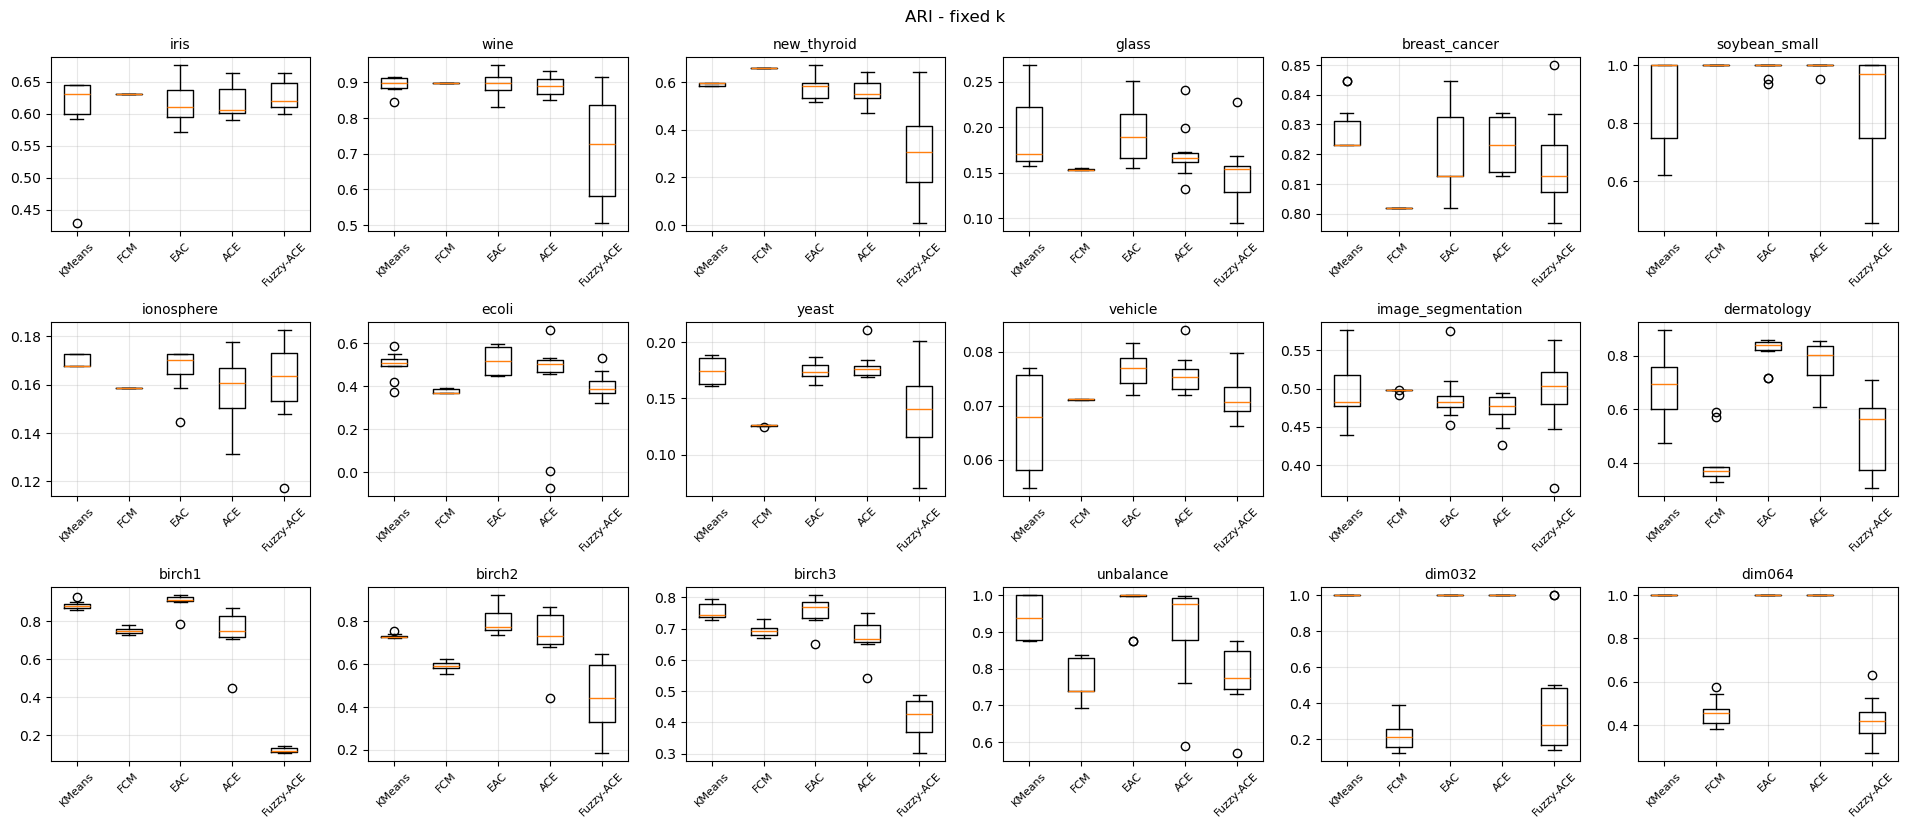

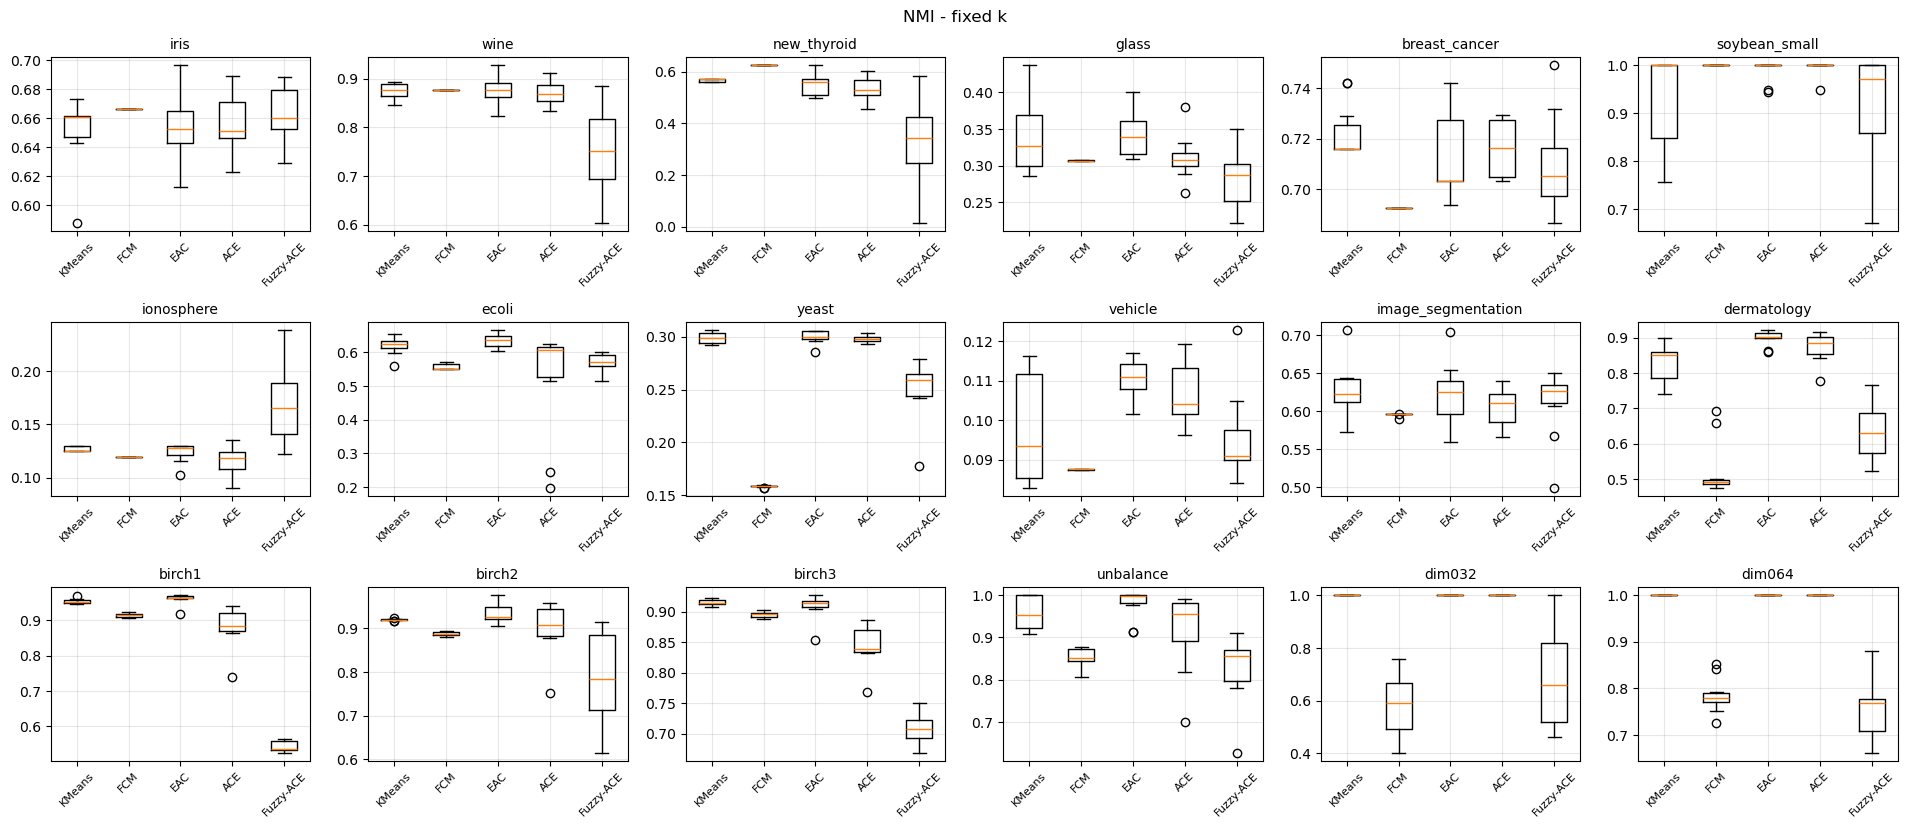

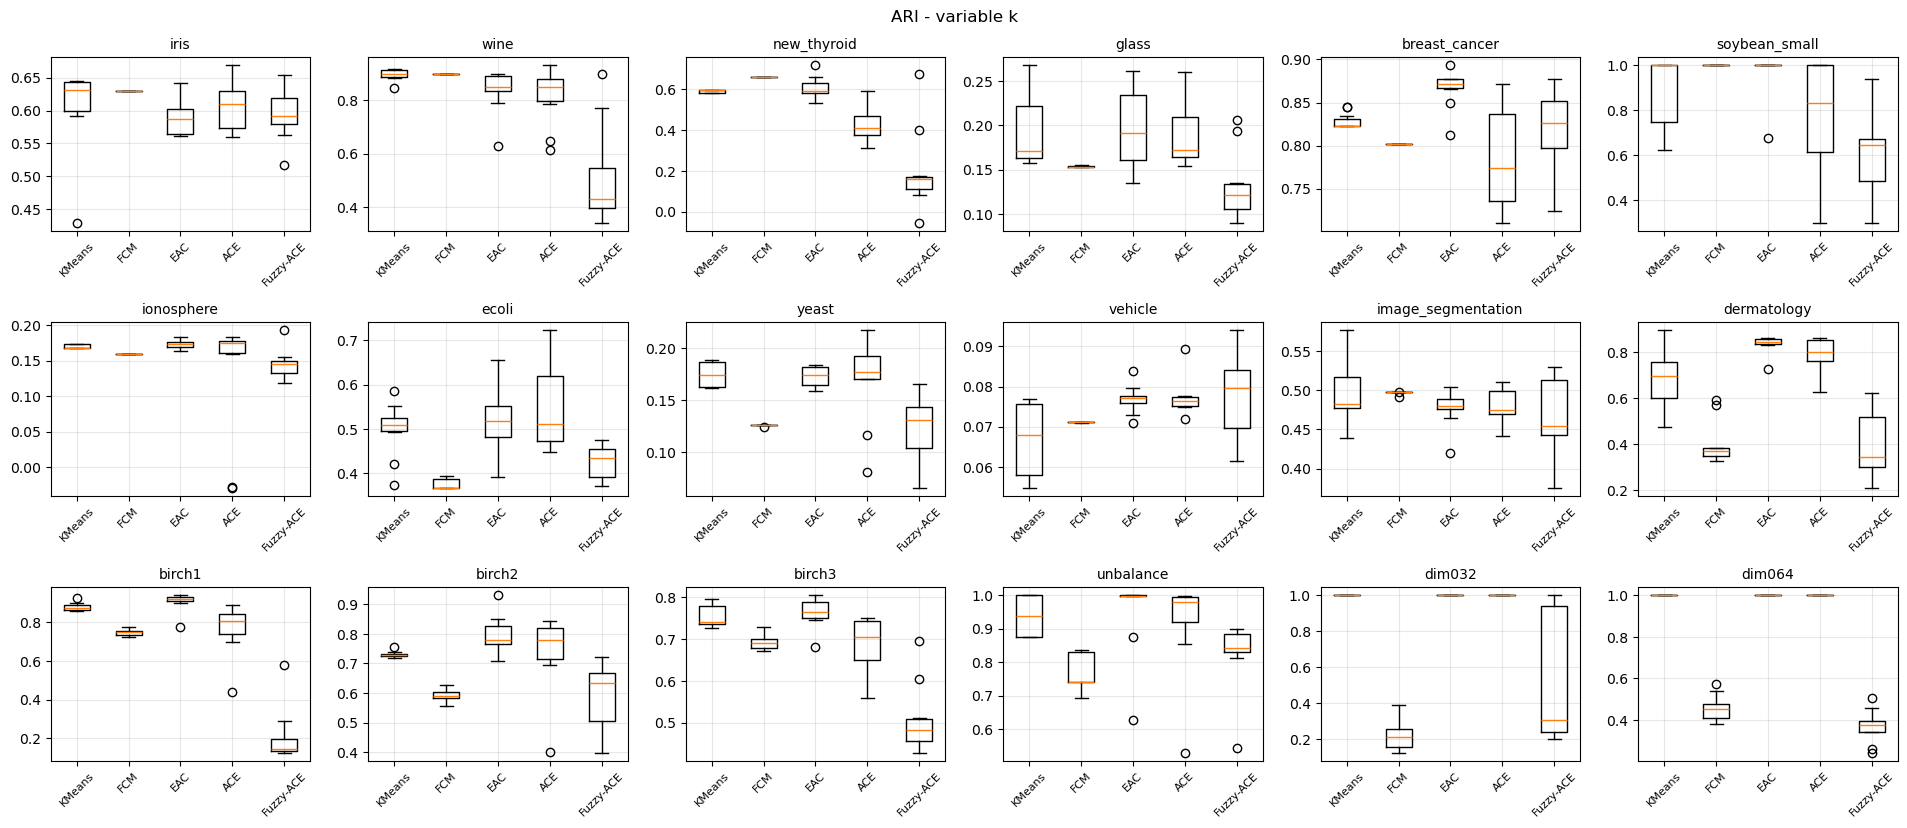

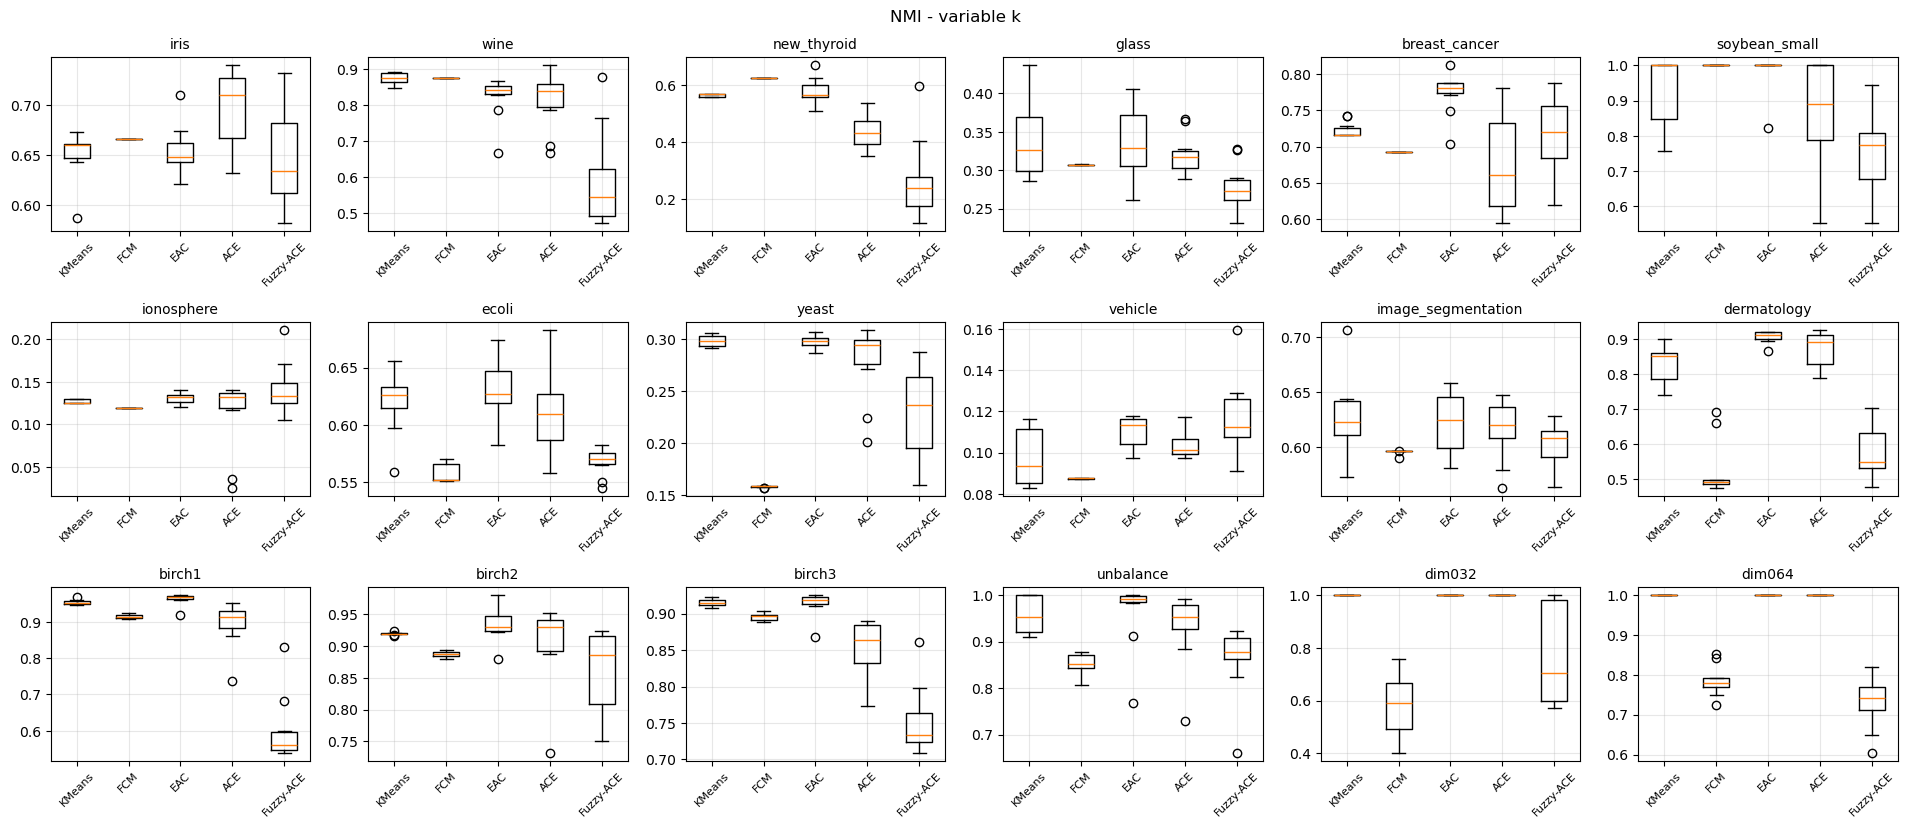

In [8]:
present = [d for d in DATASETS if d in raw["dataset"].unique()]
n_cols = 6
n_rows = int(np.ceil(len(present) / n_cols))
for setting in cfg.settings:
    for metric in ("ari", "nmi"):
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows), squeeze=False)
        for ax, d in zip(axes.flat, present):
            sub = ok[(ok.setting == setting) & (ok.dataset == d)]
            ax.boxplot([sub[sub.method == m][metric] for m in METHODS], tick_labels=list(METHODS))
            ax.set_title(d, fontsize=10)
            ax.tick_params(axis="x", labelrotation=45, labelsize=8)
            ax.grid(alpha=0.3)
        for ax in axes.flat[len(present):]:
            ax.axis("off")
        fig.suptitle(f"{metric.upper()} - {setting} k")
        fig.tight_layout()
        plt.show()

## 3. Statistical tests (Iman-Davenport + Nemenyi, CD diagrams)

Results of the subsets go to `statistics_<subset>/`; all datasets go to `statistics/`.

In [9]:
for tag, subset in STATS_SUBSETS.items():
    subset = [d for d in subset if d in present]
    if len(subset) < 2:
        continue
    print(f"\n=== {tag or 'all datasets'} ({len(subset)} datasets)")
    for r in run_statistical_tests(str(exp_dir), alpha=STATS_ALPHA, datasets=subset, tag=tag):
        verdict = "REJECT H0" if r.reject_h0 else "no significant difference"
        pairs = "; ".join(f"{a} > {b}" for a, b, _ in r.significant_pairs) or "none"
        print(f"{r.metric.upper():3s} {r.setting:8s} Iman-Davenport p={r.iman_davenport_p:.4f} -> {verdict}; "
              f"CD={r.critical_difference:.3f}; significant: {pairs}")
        print("    average ranks:", ", ".join(f"{m} {v:.2f}" for m, v in r.average_ranks.items()))


=== all datasets (18 datasets)
ARI fixed    Iman-Davenport p=0.0001 -> REJECT H0; CD=1.296; significant: EAC > FCM; EAC > Fuzzy-ACE; KMeans > Fuzzy-ACE
    average ranks: EAC 1.94, KMeans 2.56, ACE 2.94, FCM 3.39, Fuzzy-ACE 4.17
NMI fixed    Iman-Davenport p=0.0000 -> REJECT H0; CD=1.296; significant: EAC > FCM; EAC > Fuzzy-ACE; KMeans > FCM; KMeans > Fuzzy-ACE
    average ranks: EAC 1.89, KMeans 2.22, ACE 3.17, FCM 3.61, Fuzzy-ACE 4.11
ARI variable Iman-Davenport p=0.0000 -> REJECT H0; CD=1.296; significant: ACE > Fuzzy-ACE; EAC > Fuzzy-ACE; KMeans > Fuzzy-ACE
    average ranks: EAC 1.94, KMeans 2.39, ACE 3.06, FCM 3.22, Fuzzy-ACE 4.39
NMI variable Iman-Davenport p=0.0000 -> REJECT H0; CD=1.296; significant: EAC > ACE; EAC > FCM; EAC > Fuzzy-ACE; KMeans > FCM; KMeans > Fuzzy-ACE
    average ranks: EAC 1.78, KMeans 2.22, ACE 3.22, FCM 3.67, Fuzzy-ACE 4.11

=== ace_paper (7 datasets)
ARI fixed    Iman-Davenport p=0.2125 -> no significant difference; CD=2.078; significant: none
    aver

,setting,metric,N,k,friedman_chi2,friedman_p,iman_davenport_F,iman_davenport_p,reject_h0,CD,best_method,significant_pairs,rank_EAC,rank_KMeans,rank_ACE,rank_FCM,rank_Fuzzy-ACE
0,fixed,ari,18,5,20.3556,4.2482e-04,6.7005,1.3162e-04,True,1.296,EAC,EAC > FCM; EAC > Fuzzy-ACE; KMeans > Fuzzy-ACE,1.9444,2.5556,2.9444,3.3889,4.1667
1,fixed,nmi,18,5,25.0222,4.9795e-05,9.0549,6.3503e-06,True,1.296,EAC,EAC > FCM; EAC > Fuzzy-ACE; KMeans > FCM; KMea...,1.8889,2.2222,3.1667,3.6111,4.1111
2,variable,ari,18,5,24.9778,5.0830e-05,9.0302,6.5470e-06,True,1.296,EAC,ACE > Fuzzy-ACE; EAC > Fuzzy-ACE; KMeans > Fuz...,1.9444,2.3889,3.0556,3.2222,4.3889
3,variable,nmi,18,5,27.5556,1.5346e-05,10.5400,1.0544e-06,True,1.296,EAC,EAC > ACE; EAC > FCM; EAC > Fuzzy-ACE; KMeans ...,1.7778,2.2222,3.2222,3.6667,4.1111


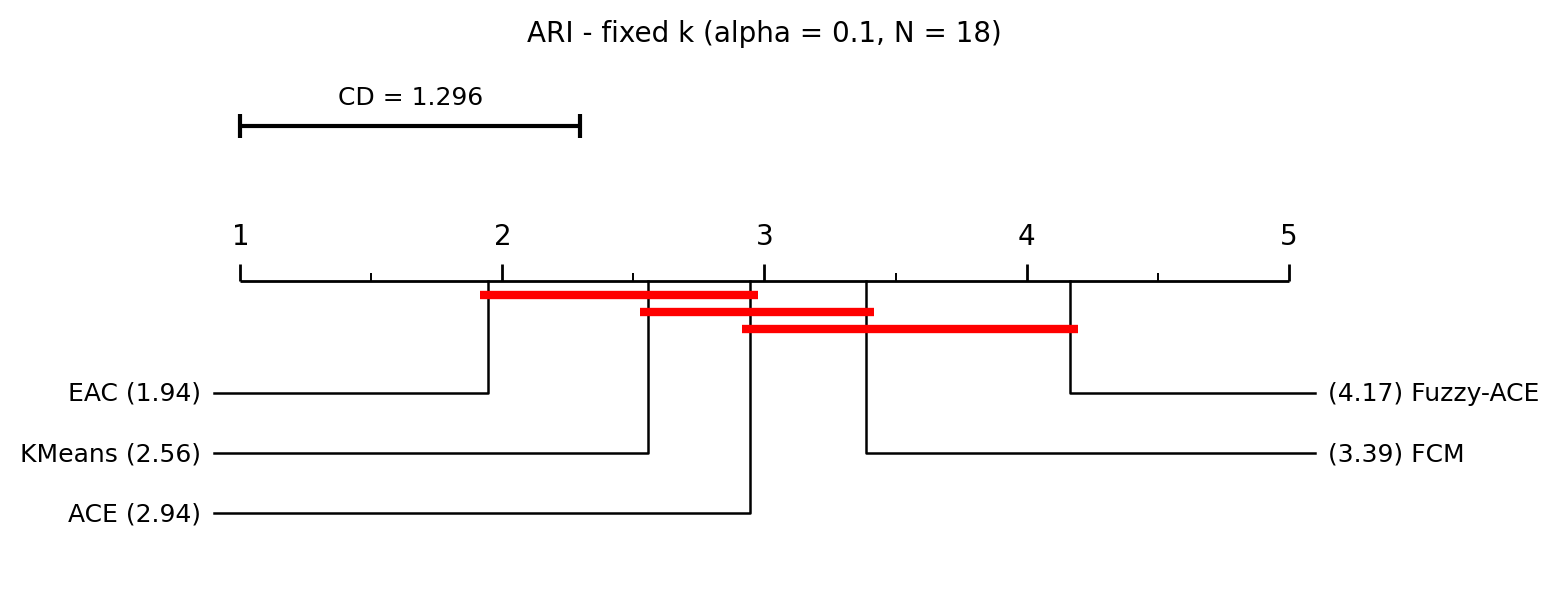

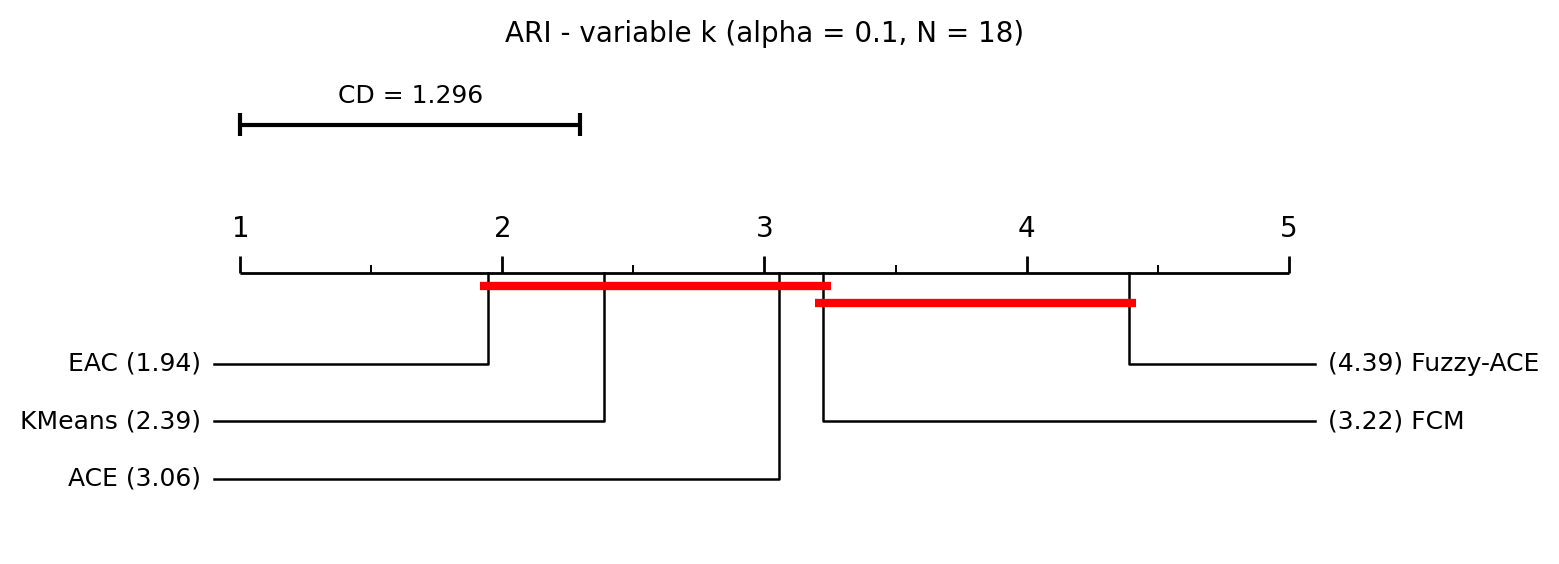

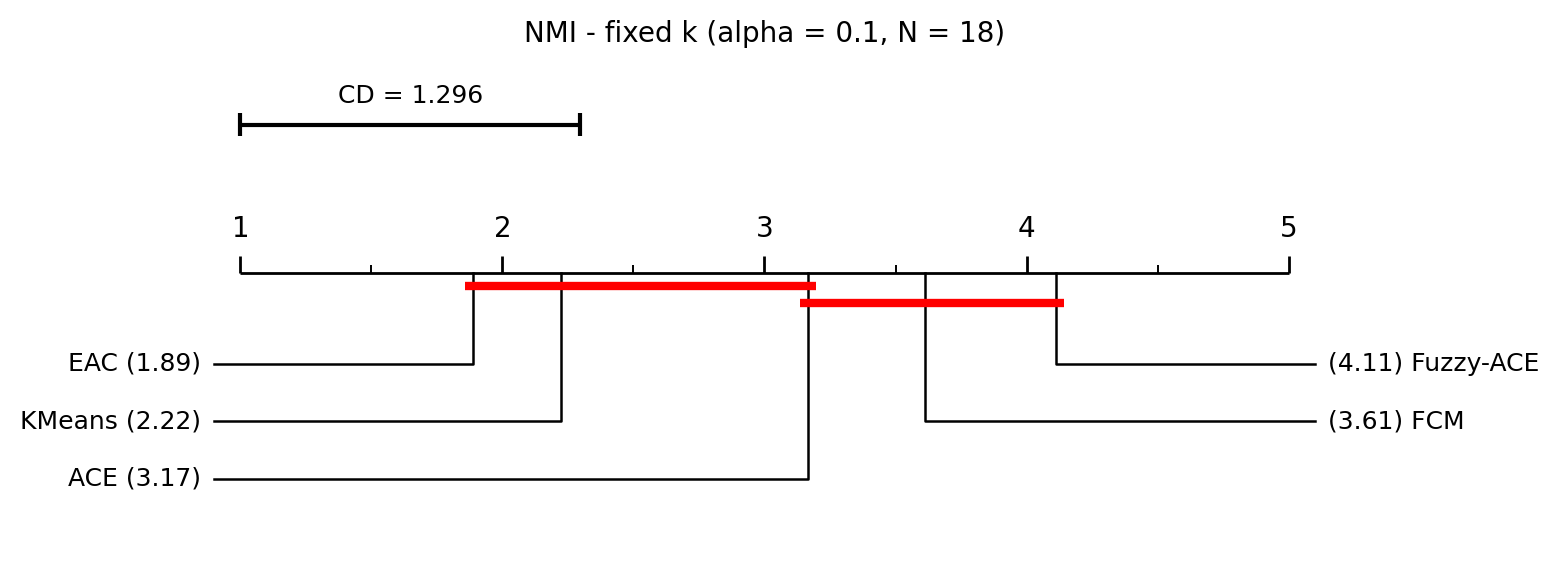

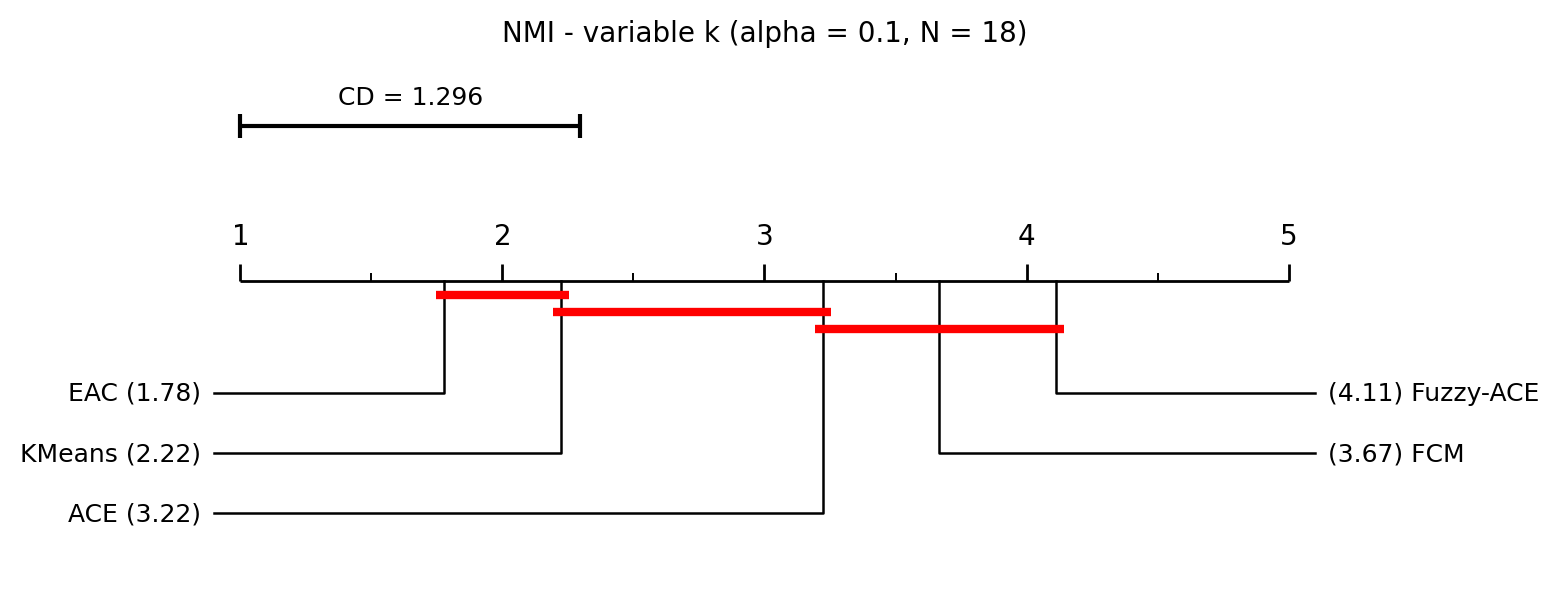

In [10]:
display(pd.read_csv(exp_dir / "statistics" / "tests_summary.csv"))
for png in sorted((exp_dir / "statistics" / "cd_diagrams").glob("*.png")):
    display(Image(filename=str(png)))

## 4. α₂ sensitivity (ACE and Fuzzy-ACE)

Stages 1-2 are fitted once per run; only Stage 3 is repeated for each α₂ value.

In [11]:
grid_cfg = ExperimentConfig(name=grid_dir.name, datasets=ALPHA2_DATASETS, settings=ALPHA2_SETTINGS,
                            methods=["ACE", "Fuzzy-ACE"], n_runs=N_RUNS, n_jobs=N_JOBS,
                            max_instances=MAX_INSTANCES, results_dir=str(RESULTS_DIR))
grid_raw = run_alpha2_grid_search(grid_cfg, alpha_2_values=ALPHA2_VALUES, verbose=VERBOSE)
display(pd.read_csv(grid_dir / "average_ranks.csv"))
pd.read_csv(grid_dir / "stability.csv").query("metric == 'ari'")

[full_alpha2] 720 ensemble fits to do -> C:\Users\lukas\PycharmProjects\FuzzyAdaptiveClusteringEnsemble\results\full_alpha2
  [1/720] iris               ACE       run 0: best alpha_2=0.5 ARI=0.6302 ok
  [2/720] iris               ACE       run 1: best alpha_2=0.5 ARI=0.6018 ok
  [3/720] iris               ACE       run 2: best alpha_2=0.5 ARI=0.6639 ok
  [4/720] iris               ACE       run 6: best alpha_2=0.5 ARI=0.6410 ok
  [5/720] iris               ACE       run 3: best alpha_2=0.5 ARI=0.6100 ok
  [6/720] iris               ACE       run 7: best alpha_2=0.5 ARI=0.5918 ok
  [7/720] iris               ACE       run 8: best alpha_2=0.5 ARI=0.6007 ok
  [8/720] iris               ACE       run 9: best alpha_2=0.5 ARI=0.6637 ok
  [9/720] iris               Fuzzy-ACE run 3: best alpha_2=0.5 ARI=0.6637 ok
  [10/720] iris               Fuzzy-ACE run 0: best alpha_2=0.5 ARI=0.6302 ok
  [11/720] iris               ACE       run 4: best alpha_2=0.5 ARI=0.5899 ok
  [12/720] iris            

,setting,method,metric,rank_alpha2_0.5,rank_alpha2_0.6,rank_alpha2_0.7,rank_alpha2_0.8,rank_alpha2_0.9
0,fixed,ACE,ari,3.0,3.0,3.0,3.0,3.0
1,fixed,ACE,nmi,3.0,3.0,3.0,3.0,3.0
2,fixed,Fuzzy-ACE,ari,3.0,3.0,3.0,3.0,3.0
3,fixed,Fuzzy-ACE,nmi,3.0,3.0,3.0,3.0,3.0
4,variable,ACE,ari,3.0,3.0,3.0,3.0,3.0
5,variable,ACE,nmi,3.0,3.0,3.0,3.0,3.0
6,variable,Fuzzy-ACE,ari,3.0,3.0,3.0,3.0,3.0
7,variable,Fuzzy-ACE,nmi,3.0,3.0,3.0,3.0,3.0


,setting,dataset,method,metric,best_alpha_2,best,worst,range,at_0.7
0,fixed,birch1,ACE,ari,0.5,0.7451,0.7451,0.0,0.7451
2,fixed,birch1,Fuzzy-ACE,ari,0.5,0.1191,0.1191,0.0,0.1191
4,fixed,birch2,ACE,ari,0.5,0.7337,0.7337,0.0,0.7337
6,fixed,birch2,Fuzzy-ACE,ari,0.5,0.4773,0.4773,0.0,0.4773
8,fixed,birch3,ACE,ari,0.5,0.6685,0.6685,0.0,0.6685
...,...,...,...,...,...,...,...,...,...
134,variable,vehicle,Fuzzy-ACE,ari,0.5,0.0780,0.0780,0.0,0.0780
136,variable,wine,ACE,ari,0.5,0.8150,0.8150,0.0,0.8150
138,variable,wine,Fuzzy-ACE,ari,0.5,0.5173,0.5173,0.0,0.5173
140,variable,yeast,ACE,ari,0.5,0.1798,0.1798,0.0,0.1798


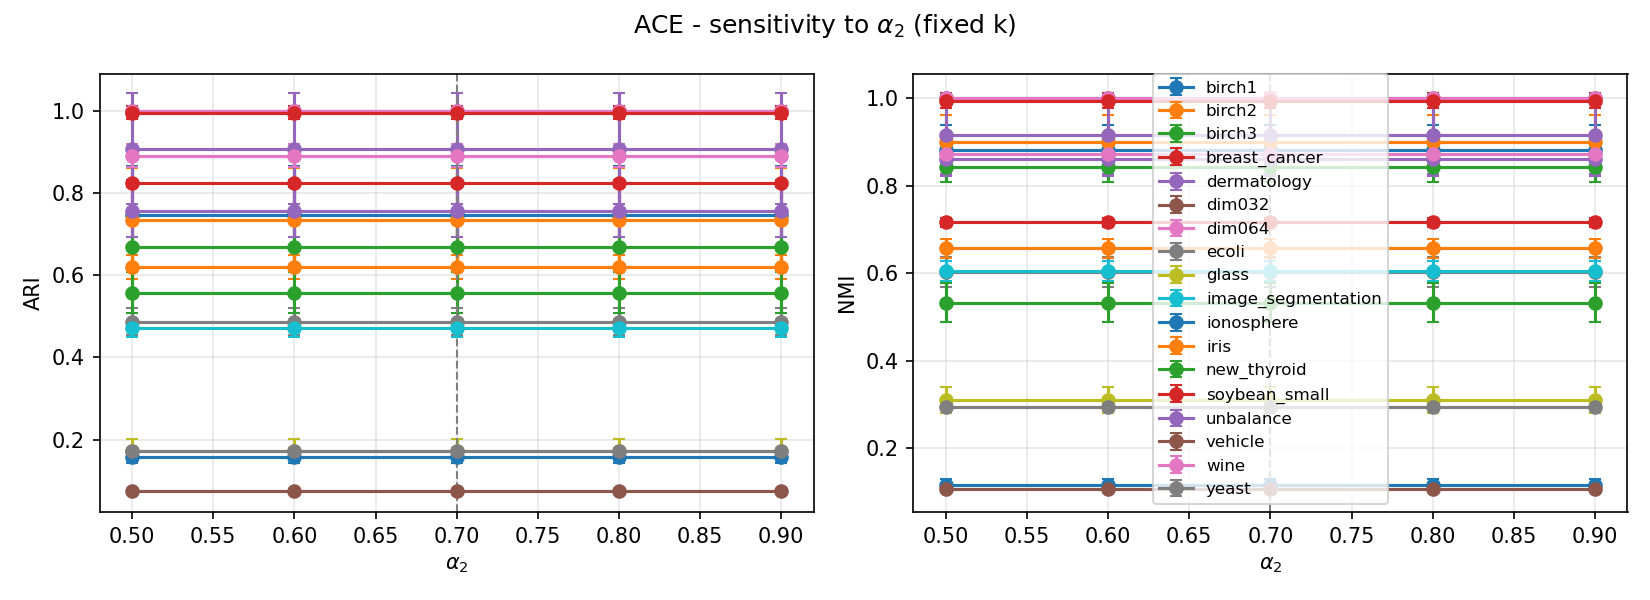

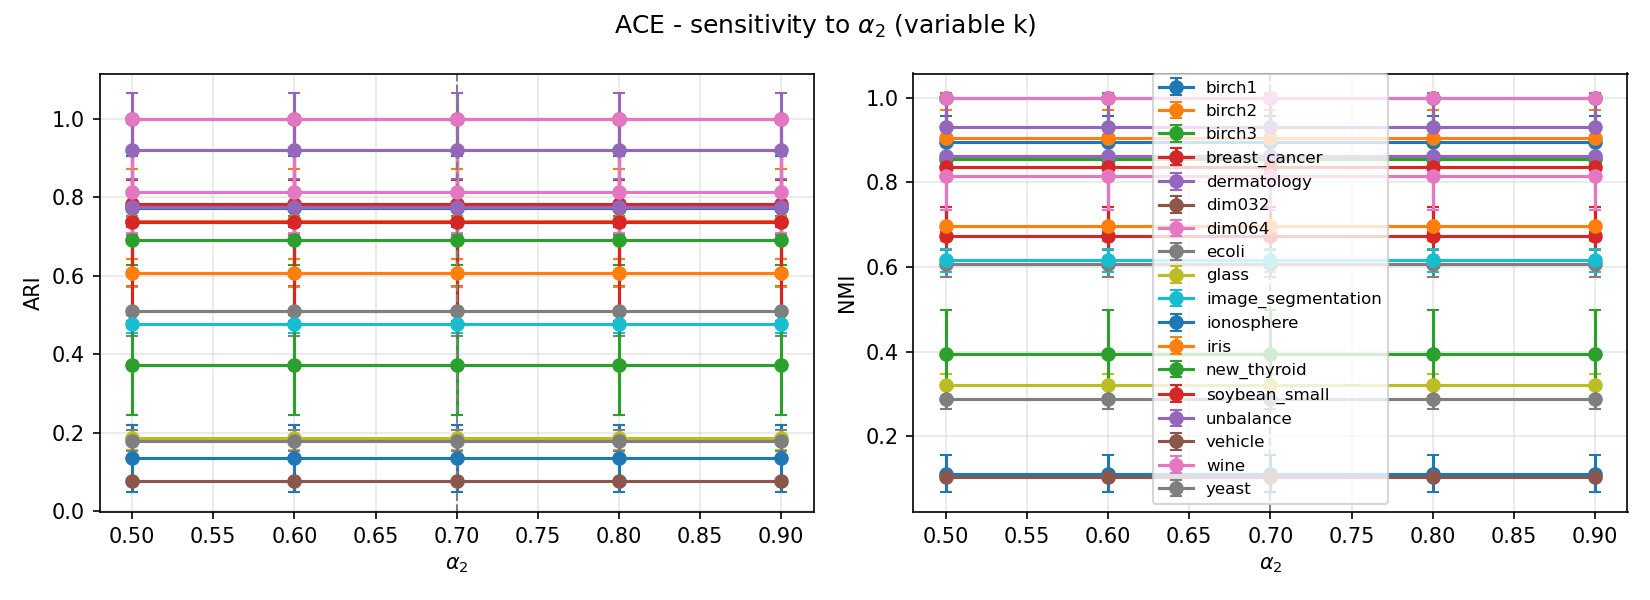

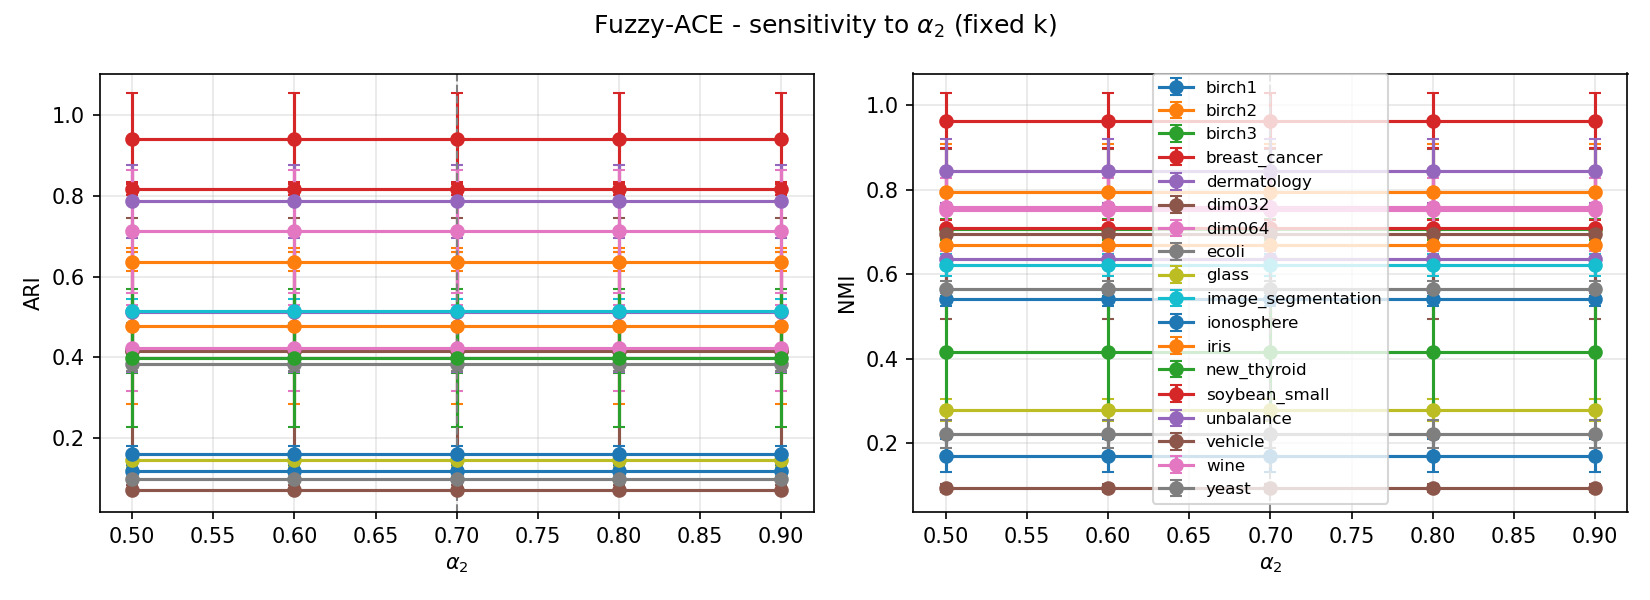

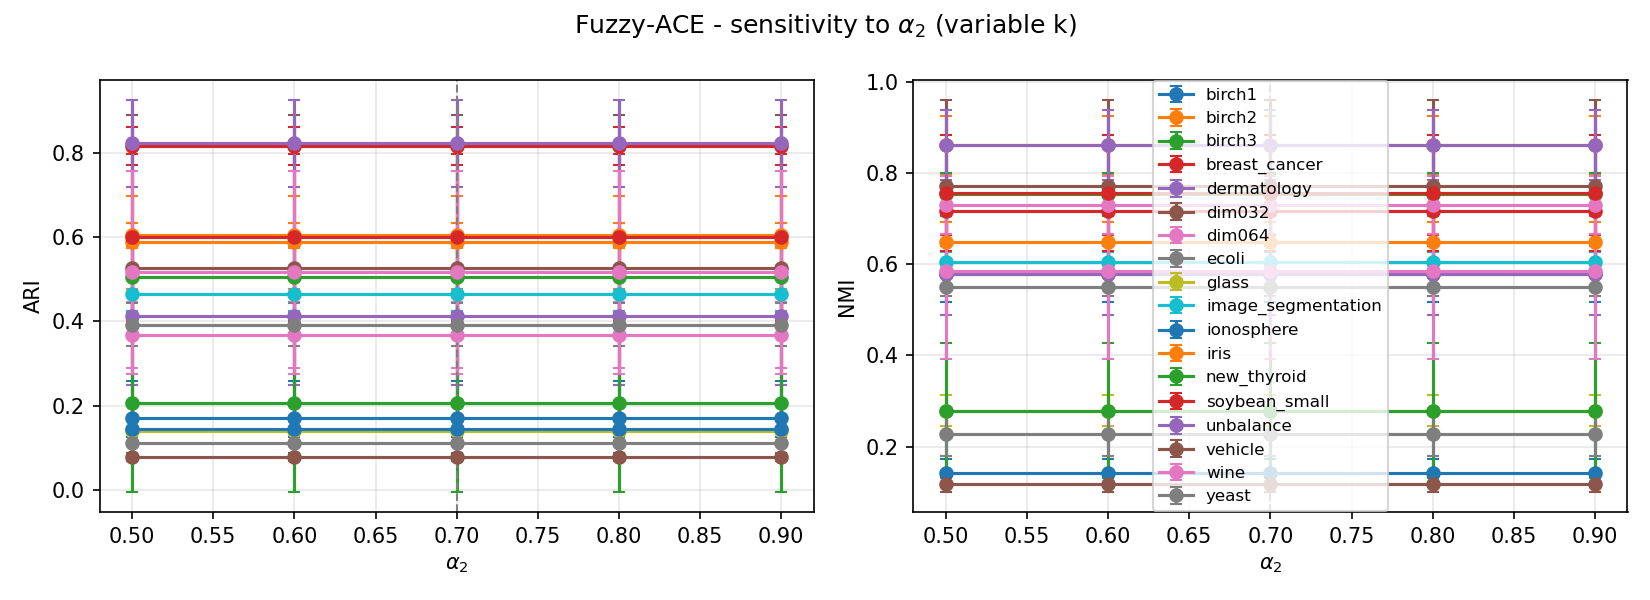

In [12]:
for png in sorted((grid_dir / "figures").glob("*.png")):
    display(Image(filename=str(png)))

## 5. Stored files

In [13]:
for d in (exp_dir, grid_dir):
    print(d.relative_to(ROOT))
    for p in sorted(d.rglob("*")):
        if p.is_file():
            print("   ", p.relative_to(d))

results\full
    config.json
    predicted_labels.csv
    raw_results.csv
    statistics\cd_diagrams\cd_ari_fixed.png
    statistics\cd_diagrams\cd_ari_variable.png
    statistics\cd_diagrams\cd_nmi_fixed.png
    statistics\cd_diagrams\cd_nmi_variable.png
    statistics\nemenyi_pvalues_ari_fixed.csv
    statistics\nemenyi_pvalues_ari_variable.csv
    statistics\nemenyi_pvalues_nmi_fixed.csv
    statistics\nemenyi_pvalues_nmi_variable.csv
    statistics\ranks_ari_fixed.csv
    statistics\ranks_ari_variable.csv
    statistics\ranks_nmi_fixed.csv
    statistics\ranks_nmi_variable.csv
    statistics\tests.json
    statistics\tests_summary.csv
    statistics_ace_paper\cd_diagrams\cd_ari_fixed.png
    statistics_ace_paper\cd_diagrams\cd_ari_variable.png
    statistics_ace_paper\cd_diagrams\cd_nmi_fixed.png
    statistics_ace_paper\cd_diagrams\cd_nmi_variable.png
    statistics_ace_paper\nemenyi_pvalues_ari_variable.csv
    statistics_ace_paper\nemenyi_pvalues_nmi_variable.csv
    statistics_

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import ALL_DATASETS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FULL_DIR = ROOT / "results" / "full"

raw = pd.read_csv(FULL_DIR / "raw_results.csv")
ok = raw[raw["status"] == "ok"]
methods = ["KMeans", "FCM", "EAC", "ACE", "Fuzzy-ACE"]
present = [d for d in ALL_DATASETS if d in ok["dataset"].unique()]

n_cols = 6
n_rows = int(np.ceil(len(present) / n_cols))

for setting in ("fixed", "variable"):
    for metric in ("ari", "nmi"):
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows), squeeze=False)
        for ax, d in zip(axes.flat, present):
            sub = ok[(ok["setting"] == setting) & (ok["dataset"] == d)]
            ax.boxplot([sub[sub["method"] == m][metric] for m in methods], tick_labels=methods)
            ax.set_title(d, fontsize=10)
            ax.tick_params(axis="x", labelrotation=45, labelsize=8)
            ax.grid(alpha=0.3)
        for ax in axes.flat[len(present):]:
            ax.axis("off")
        fig.suptitle(f"{metric.upper()} - {setting} k", fontsize=13)
        fig.tight_layout()
        fig.savefig(FULL_DIR / f"boxplot_{metric}_{setting}.png", dpi=300, bbox_inches="tight")
        plt.close(fig)